# 05 · Air Passengers — Time-Series Analysis and Forecasting

**Question.** Describe the structure of a monthly passenger series and forecast it with a model that must work on
years it has never seen.

**Data.** The classic AirPassengers series: monthly international airline passengers (thousands), 1949–1960.

**Approach.** Decomposition into trend, seasonality and residual → stationarity test (ADF) → autocorrelation →
lag, rolling-mean and calendar features → linear regression with a strictly time-ordered split → forecast on a
three-year hold-out period and an analysis of where it fails.

**Result.** MAE 7.6 on training (1953–1956), 4.5 on validation (1957) and **12.0 on the hold-out
period 1958–1960** (targets: ≤ 20 and ≤ 35).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Loading and preparing the series

In [2]:
data = pd.read_csv("../data/AirPassengers.csv")

print("Table shape:", data.shape)
print("\nData types:")
print(data.dtypes.to_string())
data.head()

Table shape: (144, 2)

Data types:
Month            str
#Passengers    int64


,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
print("Missing values per column:")
print(data.isna().sum().to_string())

before = len(data)
data = data.dropna()
print(f"\n{before} rows before dropping missing values, {len(data)} after.")

Missing values per column:
Month          0
#Passengers    0

144 rows before dropping missing values, 144 after.


In [4]:
data["Month"] = pd.to_datetime(data["Month"])
data = data.set_index("Month").sort_index()

print("Index is monotonically increasing:", data.index.is_monotonic_increasing)
print("Period covered:", data.index.min().date(), "—", data.index.max().date())

Index is monotonically increasing: True
Period covered: 1949-01-01 — 1960-12-01


In [5]:
series = data.loc["1952":"1957", "#Passengers"]

print("Analysis window:", series.index.min().date(), "—", series.index.max().date())
print("Observations:", len(series))
print(f"Values: from {series.min()} to {series.max()}")
print(f"Mean in 1952: {series['1952'].mean():.1f}")
print(f"Mean in 1957: {series['1957'].mean():.1f}")

Analysis window: 1952-01-01 — 1957-12-01
Observations: 72
Values: from 171 to 467
Mean in 1952: 197.0
Mean in 1957: 368.4


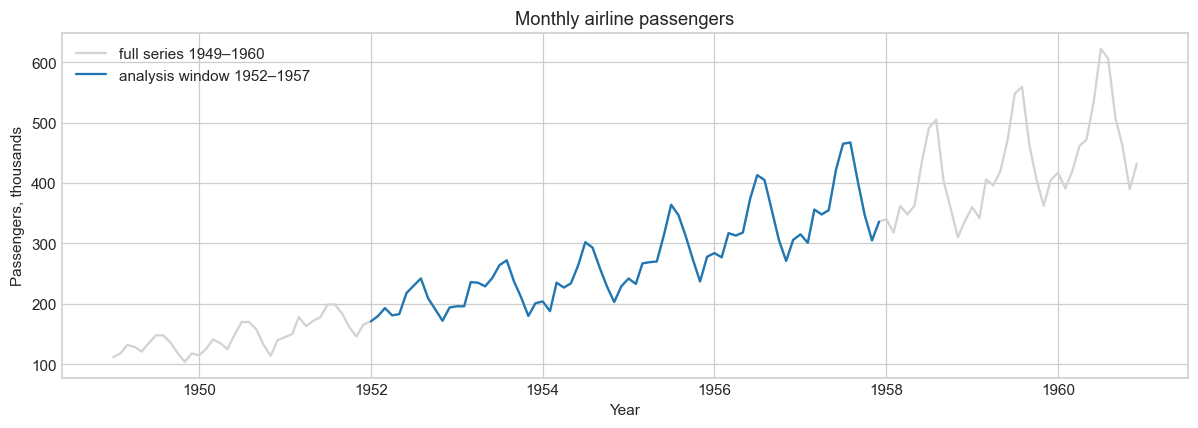

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(data.index, data["#Passengers"], color="lightgray", label="full series 1949–1960")
ax.plot(series.index, series.values, color="C0", label="analysis window 1952–1957")
ax.set_title("Monthly airline passengers")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers, thousands")
ax.legend()
fig.tight_layout()
plt.show()

## 2. Trend, seasonality and stationarity

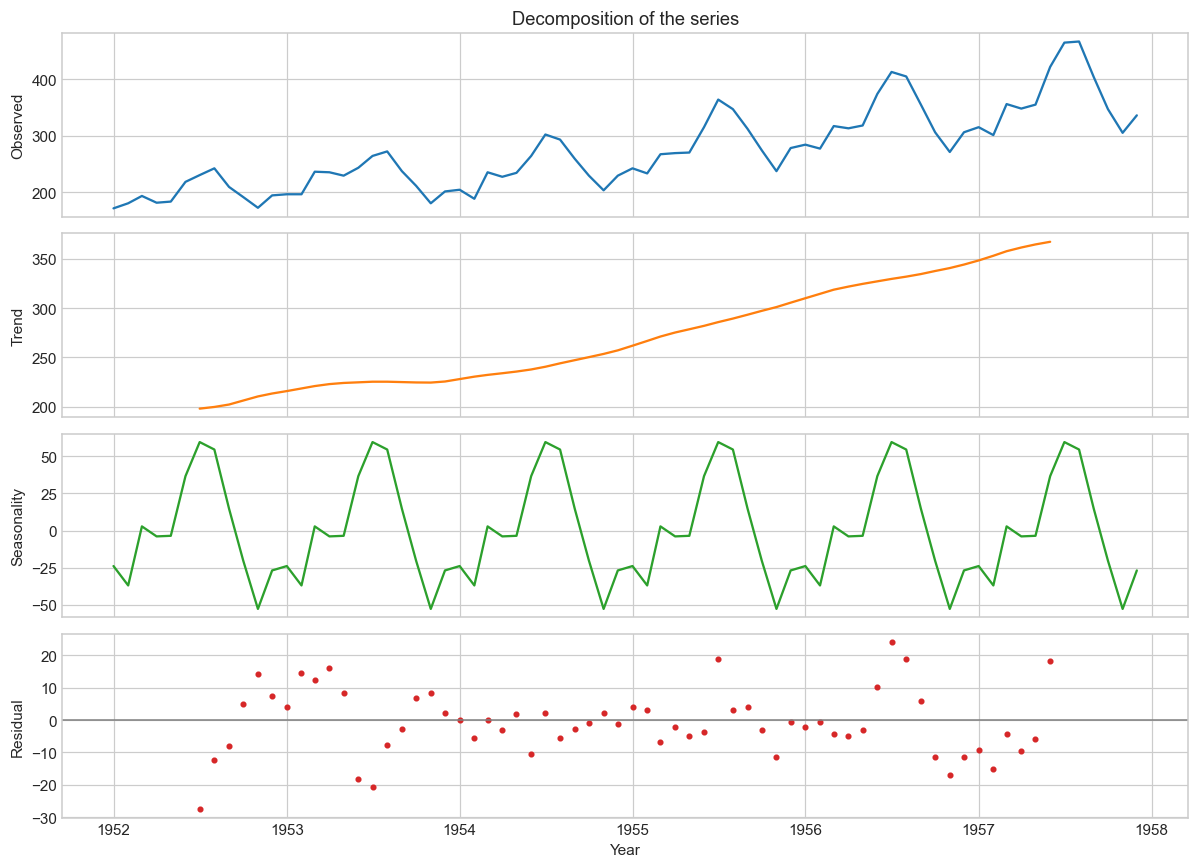

In [7]:
decomposition = seasonal_decompose(series, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
axes[0].plot(series, color="C0")
axes[0].set_ylabel("Observed")
axes[1].plot(decomposition.trend, color="C1")
axes[1].set_ylabel("Trend")
axes[2].plot(decomposition.seasonal, color="C2")
axes[2].set_ylabel("Seasonality")
axes[3].plot(decomposition.resid, color="C3", marker="o", markersize=3, linestyle="none")
axes[3].axhline(0, color="gray", linewidth=1)
axes[3].set_ylabel("Residual")
axes[3].set_xlabel("Year")
axes[0].set_title("Decomposition of the series")
fig.tight_layout()
plt.show()

In [8]:
trend = decomposition.trend.dropna()
print(f"The trend rose from {trend.iloc[0]:.1f} to {trend.iloc[-1]:.1f} "
      f"(+{trend.iloc[-1] - trend.iloc[0]:.1f} passengers over the period)")

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
print("\nSeasonal effect by month (passengers added or removed):")
for m, v in seasonal_by_month.items():
    print(f"  {m:2d}: {v:+7.1f}")
print(f"\nSeasonal amplitude: {seasonal_by_month.max() - seasonal_by_month.min():.1f}")
print(f"Residual standard deviation: {decomposition.resid.dropna().std():.2f}")

The trend rose from 198.0 to 367.2 (+169.1 passengers over the period)

Seasonal effect by month (passengers added or removed):
   1:   -23.9
   2:   -36.9
   3:    +2.8
   4:    -3.9
   5:    -3.5
   6:   +36.6
   7:   +59.5
   8:   +54.5
   9:   +14.7
  10:   -20.3
  11:   -52.7
  12:   -26.8

Seasonal amplitude: 112.2
Residual standard deviation: 10.22


In [9]:
def adf_report(x, name):
    stat, pvalue, _, _, crit, _ = adfuller(x, autolag="AIC")
    print(f"{name}:")
    print(f"  statistic = {stat:.3f}, p-value = {pvalue:.4f}")
    print(f"  verdict: series is {'stationary' if pvalue < 0.05 else 'NOT stationary'} (threshold p = 0.05)\n")

adf_report(series, "Original series")
adf_report(series.diff().dropna(), "After first differencing")
adf_report(series.diff(12).dropna(), "After seasonal differencing (lag 12)")

Original series:
  statistic = 0.859, p-value = 0.9925
  verdict: series is NOT stationary (threshold p = 0.05)

After first differencing:
  statistic = -1.671, p-value = 0.4463
  verdict: series is NOT stationary (threshold p = 0.05)

After seasonal differencing (lag 12):
  statistic = -2.458, p-value = 0.1261
  verdict: series is NOT stationary (threshold p = 0.05)



The series is not stationary, for two reasons: its mean is not constant (the trend), and its spread is not constant
either (the seasonal swings grow over time).

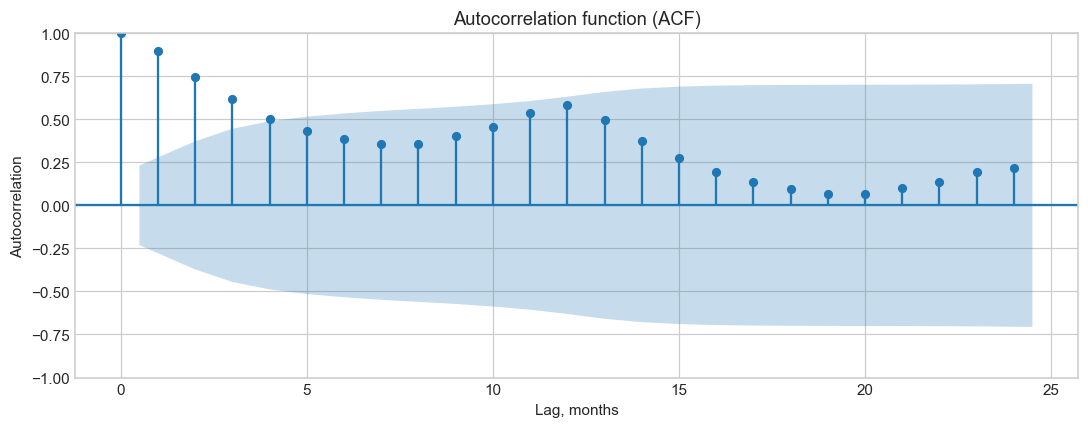

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(series, lags=24, ax=ax)
ax.set_title("Autocorrelation function (ACF)")
ax.set_xlabel("Lag, months")
ax.set_ylabel("Autocorrelation")
fig.tight_layout()
plt.show()

In [11]:
acf_values = acf(series, nlags=24)
best_lag = int(np.argmax(acf_values[1:]) + 1)

print("Autocorrelation by lag:")
for lag in range(1, 25):
    mark = "  <-- maximum" if lag == best_lag else ("  <-- yearly cycle" if lag in (12, 24) else "")
    print(f"  lag {lag:2d}: {acf_values[lag]:6.3f}{mark}")

print(f"\nThe highest autocorrelation is at lag {best_lag} "
      f"({acf_values[best_lag]:.3f}).")
print(f"Local peak at lag 12: {acf_values[12]:.3f}")

Autocorrelation by lag:
  lag  1:  0.894  <-- maximum
  lag  2:  0.745
  lag  3:  0.615
  lag  4:  0.502
  lag  5:  0.430
  lag  6:  0.387
  lag  7:  0.354
  lag  8:  0.357
  lag  9:  0.400
  lag 10:  0.456
  lag 11:  0.537
  lag 12:  0.582  <-- yearly cycle
  lag 13:  0.496
  lag 14:  0.375
  lag 15:  0.276
  lag 16:  0.191
  lag 17:  0.136
  lag 18:  0.094
  lag 19:  0.064
  lag 20:  0.065
  lag 21:  0.098
  lag 22:  0.138
  lag 23:  0.193
  lag 24:  0.216  <-- yearly cycle

The highest autocorrelation is at lag 1 (0.894).
Local peak at lag 12: 0.582


Without a trend, the autocorrelation would fall to zero within two or three lags and then oscillate around it.
Here the bars decline slowly and stay positive the whole way, never turning negative — a clear sign of a trend.
The local peak at lag 12 is the yearly seasonality.

## 3. Features and a time-ordered split

In [12]:
def make_features(data, target="#Passengers", lags=(1,), rolling_windows=(3,)):
    result = data.copy()

    # calendar features
    result["year"] = result.index.year
    result["month"] = result.index.month

    # lagged values
    for n in lags:
        result[f"lag_{n}"] = result[target].shift(n)

    # rolling means, shifted so they only use past values
    for m in rolling_windows:
        result[f"rolling_mean_{m}"] = result[target].shift(1).rolling(m).mean()

    return result

In [13]:
LAGS = [1, 12, 13]
WINDOWS = [3, 12]

featured = make_features(data.loc["1952":"1957"], lags=LAGS, rolling_windows=WINDOWS)

print("Columns after feature generation:")
print(list(featured.columns))
featured.head(14)

Columns after feature generation:
['#Passengers', 'year', 'month', 'lag_1', 'lag_12', 'lag_13', 'rolling_mean_3', 'rolling_mean_12']


,#Passengers,year,month,lag_1,lag_12,lag_13,rolling_mean_3,rolling_mean_12
Month,,,,,,,,
1952-01-01,171,1952,1,NaN,NaN,NaN,NaN,NaN
1952-02-01,180,1952,2,171.0,NaN,NaN,NaN,NaN
1952-03-01,193,1952,3,180.0,NaN,NaN,NaN,NaN
1952-04-01,181,1952,4,193.0,NaN,NaN,181.333333,NaN
1952-05-01,183,1952,5,181.0,NaN,NaN,184.666667,NaN
1952-06-01,218,1952,6,183.0,NaN,NaN,185.666667,NaN
1952-07-01,230,1952,7,218.0,NaN,NaN,194.000000,NaN
1952-08-01,242,1952,8,230.0,NaN,NaN,210.333333,NaN
1952-09-01,209,1952,9,242.0,NaN,NaN,230.000000,NaN


In [14]:
before = len(featured)
featured = featured.dropna()

print(f"{before} rows before, {len(featured)} after ({before - len(featured)} removed).")
print("Period after dropping:", featured.index.min().date(), "—", featured.index.max().date())

72 rows before, 59 after (13 removed).
Period after dropping: 1953-02-01 — 1957-12-01


In [15]:
X = featured.drop(columns="#Passengers")
y = featured["#Passengers"]

print("Features X:", X.shape, "->", list(X.columns))
print("Target y:", y.shape)

Features X: (59, 7) -> ['year', 'month', 'lag_1', 'lag_12', 'lag_13', 'rolling_mean_3', 'rolling_mean_12']
Target y: (59,)


The split is by date, not random: the model must never see the future while learning.

In [16]:
split_date = "1957-01-01"

X_train, y_train = X[X.index < split_date], y[y.index < split_date]
X_valid, y_valid = X[X.index >= split_date], y[y.index >= split_date]

print(f"Training:   {X_train.index.min().date()} — {X_train.index.max().date()}  "
      f"({len(X_train)} observations)")
print(f"Validation: {X_valid.index.min().date()} — {X_valid.index.max().date()}  "
      f"({len(X_valid)} observations)")

Training:   1953-02-01 — 1956-12-01  (47 observations)
Validation: 1957-01-01 — 1957-12-01  (12 observations)


## 4. Model

In [17]:
model = LinearRegression()
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_valid = model.predict(X_valid)

mae_train = mean_absolute_error(y_train, pred_train)
mae_valid = mean_absolute_error(y_valid, pred_valid)

print(f"MAE, training:   {mae_train:.2f}")
print(f"MAE, validation: {mae_valid:.2f}")
print(f"\nTarget: MAE <= 20. Result: {'met' if max(mae_train, mae_valid) <= 20 else 'NOT met'}.")

MAE, training:   7.62
MAE, validation: 4.49

Target: MAE <= 20. Result: met.


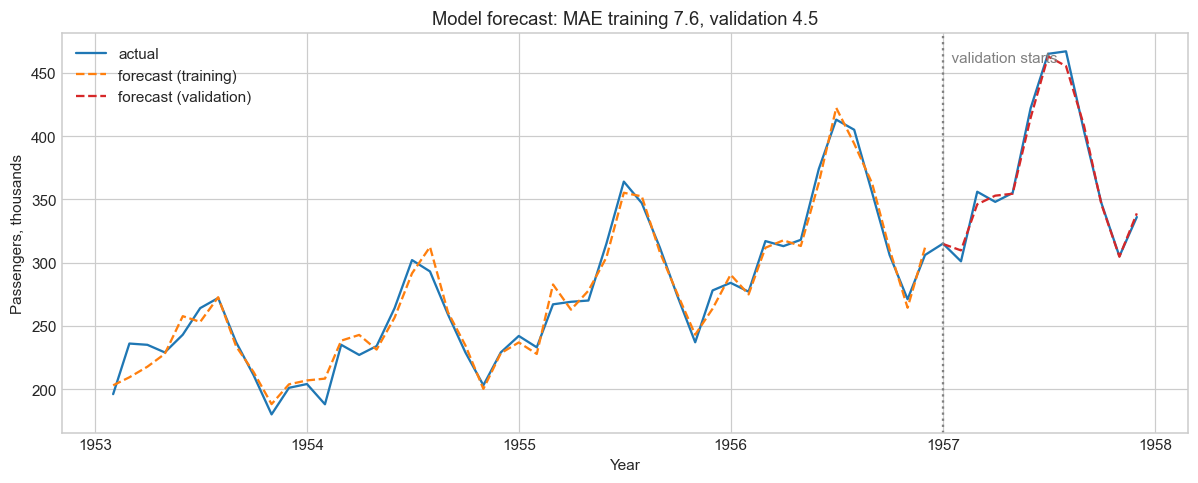

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y.index, y.values, color="C0", label="actual")
ax.plot(X_train.index, pred_train, color="C1", linestyle="--", label="forecast (training)")
ax.plot(X_valid.index, pred_valid, color="C3", linestyle="--", label="forecast (validation)")
ax.axvline(pd.Timestamp(split_date), color="gray", linestyle=":")
ax.text(pd.Timestamp(split_date), y.max(), "  validation starts", color="gray", va="top")
ax.set_title(f"Model forecast: MAE training {mae_train:.1f}, validation {mae_valid:.1f}")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers, thousands")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Forecast on unseen years (1958–1960)

The hold-out features are built from a window starting in 1956, so the lags for January 1958 come from real 1956–1957
values; only the 1958–1960 rows are scored.

In [19]:
holdout_raw = data.loc["1956":"1960"]
print("Window taken:", holdout_raw.index.min().date(), "—", holdout_raw.index.max().date(),
      f"({len(holdout_raw)} observations)")

Window taken: 1956-01-01 — 1960-12-01 (60 observations)


In [20]:
holdout = make_features(holdout_raw, lags=LAGS, rolling_windows=WINDOWS).dropna()
holdout = holdout.loc["1958":]

print("  period:", holdout.index.min().date(), "—", holdout.index.max().date())
print("  observations:", len(holdout))

  period: 1958-01-01 — 1960-12-01
  observations: 36


In [21]:
X_holdout = holdout.drop(columns="#Passengers")
y_holdout = holdout["#Passengers"]

# column order must match the training data
X_holdout = X_holdout[X_train.columns]

pred_holdout = model.predict(X_holdout)
mae_holdout = mean_absolute_error(y_holdout, pred_holdout)

print(f"MAE, hold-out: {mae_holdout:.2f}")
print(f"\nTarget: MAE <= 35. Result: {'met' if mae_holdout <= 35 else 'NOT met'}.")

MAE, hold-out: 11.98

Target: MAE <= 35. Result: met.


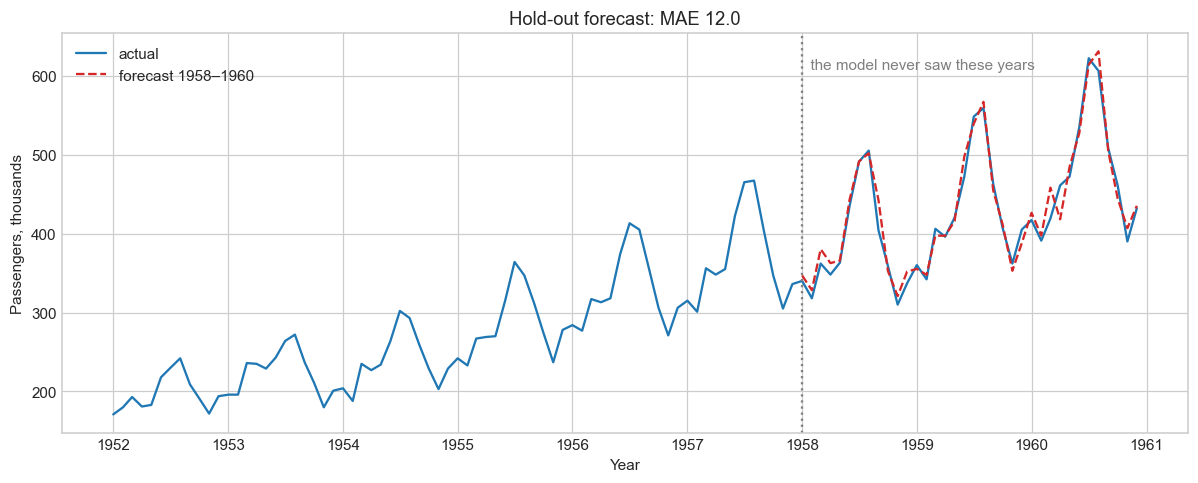

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(data.loc["1952":"1960"].index, data.loc["1952":"1960", "#Passengers"],
        color="C0", label="actual")
ax.plot(holdout.index, pred_holdout, color="C3", linestyle="--", label="forecast 1958–1960")
ax.axvline(pd.Timestamp("1958-01-01"), color="gray", linestyle=":")
ax.text(pd.Timestamp("1958-01-01"), data["#Passengers"].max(),
        "  the model never saw these years", color="gray", va="top")
ax.set_title(f"Hold-out forecast: MAE {mae_holdout:.1f}")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers, thousands")
ax.legend()
fig.tight_layout()
plt.show()

In [23]:
errors = pd.DataFrame({
    "actual": y_holdout,
    "forecast": pred_holdout.round(1),
    "error": (y_holdout - pred_holdout).round(1),
})
print("Largest forecast errors:")
print(errors.reindex(errors["error"].abs().sort_values(ascending=False).index).head(6).to_string())
print(f"\nMean bias (actual - forecast): {errors['error'].mean():+.1f}")

print("\nMean absolute error by year:")
print(errors["error"].abs().groupby(errors.index.year).mean().round(1).to_string())

print("\nHardest months (mean absolute error):")
print(errors["error"].abs().groupby(errors.index.month).mean().round(1)
      .sort_values(ascending=False).head(4).to_string())

Largest forecast errors:
            actual  forecast  error
Month                              
1960-04-01     461     418.0   43.0
1960-03-01     419     458.1  -39.1
1958-09-01     404     442.3  -38.3
1959-06-01     472     497.4  -25.4
1960-08-01     606     630.7  -24.7
1958-03-01     362     380.2  -18.2

Mean bias (actual - forecast): -3.6

Mean absolute error by year:
Month
1958    11.2
1959     8.8
1960    15.9

Hardest months (mean absolute error):
Month
3    22.0
4    19.6
9    16.7
6    13.7


## 6. Conclusions

**Structure of the series (1952–1957).**

1. **There is a trend.** The trend component rises from 198 to 367 thousand passengers; the 1957 monthly mean is
   almost twice that of 1952 (368 against 197).
2. **There is yearly seasonality.** July (+60) and August (+55) are the peak months and November (−53) the weakest;
   the seasonal amplitude is 112 thousand passengers. The swings also grow with the level of the series: the
   within-year range widens from 71 in 1952 to 166 in 1957.
3. **The series is not stationary.** The ADF test gives p = 0.99. Neither first differencing (p = 0.45) nor seasonal
   differencing (p = 0.13) makes it stationary on these 72 points.
4. **The autocorrelation confirms both.** It declines slowly and stays positive at every lag (trend), with a local
   peak at lag 12 (0.58) and a second rise towards lag 24 (seasonality).

**Forecast quality.** A linear regression on lags 1, 12 and 13, 3- and 12-month rolling means, year and month:

| Data | Period | MAE |
|---|---|---|
| Training | 1953–1956 | 7.6 |
| Validation | 1957 | 4.5 |
| Hold-out | 1958–1960 | 12.0 |

Both targets are met. Validation MAE is lower than training MAE only because it covers 12 months; the three-year
hold-out is the honest estimate of how the model performs on unseen data.

**Where the model fails.** The error grows in the last year (15.9 in 1960 against 8.8 in 1959), and the two largest
misses are back to back: March 1960 over-forecast by 39 and April 1960 under-forecast by 43. The lag-12 features
carry the previous year's shape, in which April was *below* March (−14 in 1958, −10 in 1959). In 1960 April
jumped 42 above March, so the model missed in both directions. On average it slightly over-forecasts (bias −3.6).

**Limitations.** The additive decomposition assumes constant seasonal swings, yet they clearly grow with the level;
a multiplicative model or a log transform would fit the data better. The `year` feature also extrapolates the trend as
a straight line, which becomes riskier the further ahead the forecast goes.